In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

import warnings
warnings.filterwarnings('ignore')

# %% [markdown]
"""
## Data Loading and Preparation

We load the four CSV files. (Make sure the file names and paths match your local setup.)
Since these files do not have headers, we assign column names as follows:
- "time", "pressure", "obstacle"
Then we add a sensor configuration label based on the file.
"""
# %% 
# For demonstration, we assume the files have no headers.
# Adjust the read_csv() call if your files have headers.
ac_df = pd.read_csv('C:/Users/Алишер/Desktop/NazarbayevUniversity/DatasetPdM/Class_regres_dataset/AC_Down_to_Sort - Sheet1.csv', header=0)
cb_df = pd.read_csv('C:/Users/Алишер/Desktop/NazarbayevUniversity/DatasetPdM/Class_regres_dataset/CB_Sort_to_Upstream - Sheet1.csv', header=0)
bc_df = pd.read_csv('C:/Users/Алишер/Desktop/NazarbayevUniversity/DatasetPdM/Class_regres_dataset/BC_Upstream_to_Sort - Sheet1.csv', header=0)
ca_df = pd.read_csv('C:/Users/Алишер/Desktop/NazarbayevUniversity/DatasetPdM/Class_regres_dataset/CA_Sort_to_Down - Sheet1.csv', header=0)

# Assign column names: [time, pressure, obstacle]
ac_df.columns = ['time', 'pressure', 'obstacle']
cb_df.columns = ['time', 'pressure', 'obstacle']
bc_df.columns = ['time', 'pressure', 'obstacle']
ca_df.columns = ['time', 'pressure', 'obstacle']

# Add sensor configuration labels
ac_df['sensor_config'] = 'AC'
cb_df['sensor_config'] = 'CB'
bc_df['sensor_config'] = 'BC'
ca_df['sensor_config'] = 'CA'

# %% [markdown]
"""
### Create Labeled Datasets for Mechanical Classification

For **mech_1** we use files AC and CA.
For **mech_2** we use files CB and BC.
"""
# %% 
# For mech_1 (from AC and CA), the obstacle label is used as mech_1.
df_mech1 = pd.concat([ac_df, ca_df], axis=0).copy()
df_mech1['mech_1'] = df_mech1['obstacle']
# We drop the original obstacle column (or you can keep it if desired)
df_mech1 = df_mech1.drop(columns=['obstacle'])

# For mech_2 (from CB and BC), the obstacle label is used as mech_2.
df_mech2 = pd.concat([cb_df, bc_df], axis=0).copy()
df_mech2['mech_2'] = df_mech2['obstacle']
df_mech2 = df_mech2.drop(columns=['obstacle'])


In [3]:
### Create Dataset for Pressure Regression
"""
### Create Dataset for Pressure Regression

We combine all files to build a regression model to predict pressure.
We can use the sensor configuration as a categorical feature.
"""

# %% 
df_pressure = pd.concat([ac_df, cb_df, bc_df, ca_df], axis=0).copy()
# We keep only the needed columns
df_pressure = df_pressure[['time', 'sensor_config', 'pressure']]

# One-hot encode the sensor configuration
df_pressure = pd.get_dummies(df_pressure, columns=['sensor_config'])

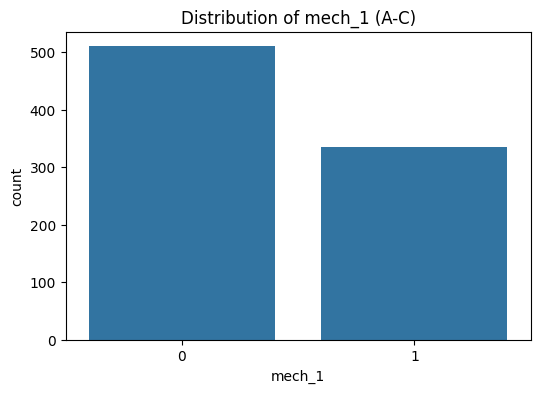

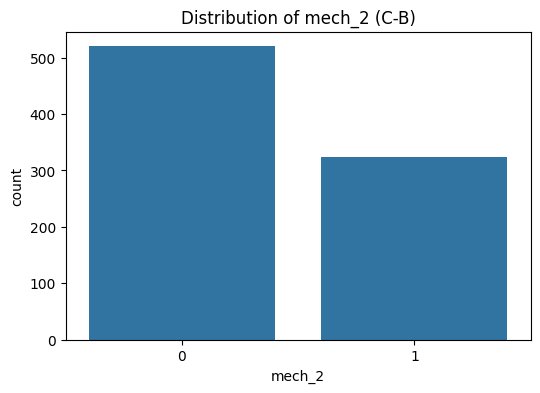

In [4]:
"""
## Exploratory Data Analysis

Let's quickly inspect the distributions in one of the datasets.
For example, check the distribution of the mechanical obstacle for mech_1.
"""
# %% 
plt.figure(figsize=(6,4))
sns.countplot(x='mech_1', data=df_mech1)
plt.title('Distribution of mech_1 (A-C)')
plt.show()

# Similarly for mech_2:
plt.figure(figsize=(6,4))
sns.countplot(x='mech_2', data=df_mech2)
plt.title('Distribution of mech_2 (C-B)')
plt.show()


In [5]:
"""
## Modeling Preparation

We will now build three separate models:
1. Classification model for mech_1 (using df_mech1).
2. Classification model for mech_2 (using df_mech2).
3. Regression model for pressure (using df_pressure).

We use a simple preprocessing pipeline (imputation and scaling) for each.
"""
# %% 
# Preprocessing pipeline for classification (assume the only feature is "time")
clf_preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# For regression, we use both "time" and the one-hot sensor config columns.
reg_preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Prepare data for mech_1 classification
X_mech1 = df_mech1[['time']]  # you can add more features if available
y_mech1 = df_mech1['mech_1']
X_mech1_train, X_mech1_test, y_mech1_train, y_mech1_test = train_test_split(
    X_mech1, y_mech1, test_size=0.2, random_state=42, stratify=y_mech1)

X_mech1_train = clf_preprocessor.fit_transform(X_mech1_train)
X_mech1_test = clf_preprocessor.transform(X_mech1_test)

# Prepare data for mech_2 classification
X_mech2 = df_mech2[['time']]
y_mech2 = df_mech2['mech_2']
X_mech2_train, X_mech2_test, y_mech2_train, y_mech2_test = train_test_split(
    X_mech2, y_mech2, test_size=0.2, random_state=42, stratify=y_mech2)

X_mech2_train = clf_preprocessor.fit_transform(X_mech2_train)
X_mech2_test = clf_preprocessor.transform(X_mech2_test)

# Prepare data for pressure regression
X_pressure = df_pressure.drop(columns=['pressure'])
y_pressure = df_pressure['pressure']
X_pressure_train, X_pressure_test, y_pressure_train, y_pressure_test = train_test_split(
    X_pressure, y_pressure, test_size=0.2, random_state=42)

X_pressure_train = reg_preprocessor.fit_transform(X_pressure_train)
X_pressure_test = reg_preprocessor.transform(X_pressure_test)


In [6]:
"""
## Model 1: Classification for mech_1

Train a Random Forest classifier to predict the presence of a mechanical obstacle (mech_1).
"""
# %% 
mech1_clf = RandomForestClassifier(n_estimators=100, random_state=42)
mech1_clf.fit(X_mech1_train, y_mech1_train)

y_mech1_pred = mech1_clf.predict(X_mech1_test)
acc_mech1 = accuracy_score(y_mech1_test, y_mech1_pred)
print(f"Accuracy for mech_1: {acc_mech1:.2f}")
print("Classification Report for mech_1:")
print(classification_report(y_mech1_test, y_mech1_pred))

Accuracy for mech_1: 0.83
Classification Report for mech_1:
              precision    recall  f1-score   support

           0       0.87      0.84      0.86       102
           1       0.77      0.81      0.79        67

    accuracy                           0.83       169
   macro avg       0.82      0.82      0.82       169
weighted avg       0.83      0.83      0.83       169



In [7]:
"""
## Model 2: Classification for mech_2

Train a Random Forest classifier to predict the presence of a mechanical obstacle (mech_2).
"""
# %% 
mech2_clf = RandomForestClassifier(n_estimators=100, random_state=42)
mech2_clf.fit(X_mech2_train, y_mech2_train)

y_mech2_pred = mech2_clf.predict(X_mech2_test)
acc_mech2 = accuracy_score(y_mech2_test, y_mech2_pred)
print(f"Accuracy for mech_2: {acc_mech2:.2f}")
print("Classification Report for mech_2:")
print(classification_report(y_mech2_test, y_mech2_pred))

Accuracy for mech_2: 0.76
Classification Report for mech_2:
              precision    recall  f1-score   support

           0       0.81      0.81      0.81       104
           1       0.69      0.69      0.69        65

    accuracy                           0.76       169
   macro avg       0.75      0.75      0.75       169
weighted avg       0.76      0.76      0.76       169



Pressure Regression Performance:
Mean Squared Error: 0.20
R-squared: 0.77


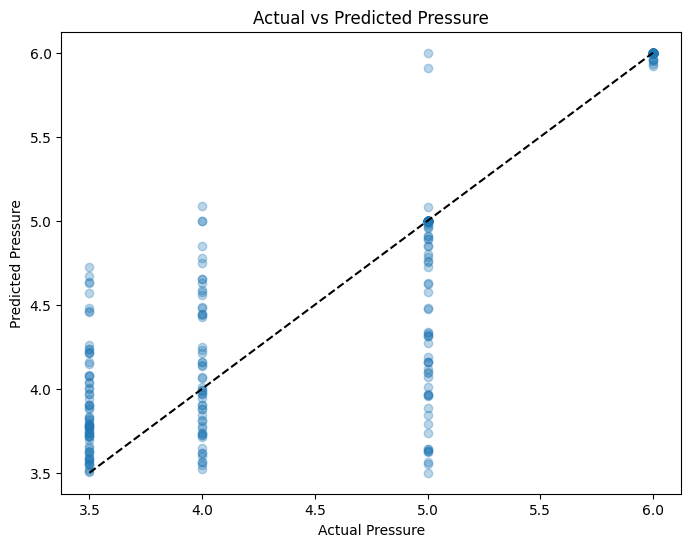

In [8]:
"""
## Model 3: Pressure Regression

Train a Random Forest regressor to predict system pressure.
"""
# %% 
pressure_reg = RandomForestRegressor(n_estimators=100, random_state=42)
pressure_reg.fit(X_pressure_train, y_pressure_train)

y_pressure_pred = pressure_reg.predict(X_pressure_test)
mse = mean_squared_error(y_pressure_test, y_pressure_pred)
r2 = r2_score(y_pressure_test, y_pressure_pred)
print("Pressure Regression Performance:")
print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

# Plot Actual vs Predicted pressure
plt.figure(figsize=(8, 6))
plt.scatter(y_pressure_test, y_pressure_pred, alpha=0.3)
plt.plot([y_pressure_test.min(), y_pressure_test.max()], 
         [y_pressure_test.min(), y_pressure_test.max()], 'k--')
plt.xlabel('Actual Pressure')
plt.ylabel('Predicted Pressure')
plt.title('Actual vs Predicted Pressure')
plt.show()


In [9]:
"""
## Model Deployment Function

This function demonstrates how to preprocess new input data and make predictions for:
- mech_1 (using the mech_1 classifier)
- mech_2 (using the mech_2 classifier)
- pressure (using the pressure regressor)

For deployment, you may have new measurements (a time value) and the sensor configuration.
"""
# %% 
def predict_system_status(time_value, sensor_config):
    """
    Predict mechanical obstacle status and pressure for a new sample.
    
    Parameters:
      - time_value: The time measurement (a numeric value).
      - sensor_config: One of 'AC', 'BC', 'CA', 'CB'.
      
    Returns:
      Dictionary with predictions for mech_1 (if sensor_config in ['AC', 'CA']),
      mech_2 (if sensor_config in ['CB', 'BC']), and pressure.
    """
    # Create a DataFrame for classification prediction (only feature is 'time')
    input_clf = pd.DataFrame({'time': [time_value]})
    input_reg = pd.DataFrame({'time': [time_value]})
    
    # For regression, add sensor configuration one-hot features.
    for config in ['AC', 'BC', 'CA', 'CB']:
        input_reg[f'sensor_config_{config}'] = [1 if sensor_config == config else 0]
    
    # Preprocess inputs
    input_clf_scaled = clf_preprocessor.transform(input_clf)
    input_reg_scaled = reg_preprocessor.transform(input_reg)
    
    predictions = {}
    
    # If the sensor configuration corresponds to mech_1 (AC or CA)
    if sensor_config in ['AC', 'CA']:
        pred_mech1 = mech1_clf.predict(input_clf_scaled)[0]
        predictions['mech_1_prediction'] = int(pred_mech1)
    else:
        predictions['mech_1_prediction'] = None
    
    # If the sensor configuration corresponds to mech_2 (CB or BC)
    if sensor_config in ['CB', 'BC']:
        pred_mech2 = mech2_clf.predict(input_clf_scaled)[0]
        predictions['mech_2_prediction'] = int(pred_mech2)
    else:
        predictions['mech_2_prediction'] = None
    
    # Pressure prediction from regression model (applies to all sensors)
    pred_pressure = pressure_reg.predict(input_reg_scaled)[0]
    predictions['pressure_prediction'] = float(pred_pressure)
    
    return predictions

# Example prediction
print("Example prediction for time_value=3000, sensor_config='AC':")
print(predict_system_status(4512, 'AC'))
print(predict_system_status(4400, 'AC'))

Example prediction for time_value=3000, sensor_config='AC':
{'mech_1_prediction': 1, 'mech_2_prediction': None, 'pressure_prediction': 4.700833333333334}
{'mech_1_prediction': 1, 'mech_2_prediction': None, 'pressure_prediction': 4.495}


In [10]:
# For mech_1 data (assuming X_mech1 and y_mech1 are defined as before)
X_mech1_train_val, X_mech1_test, y_mech1_train_val, y_mech1_test = train_test_split(
    X_mech1, y_mech1, test_size=0.2, random_state=42, stratify=y_mech1)

# Now split the train_val set further into training and validation (e.g., 80/20 split)
X_mech1_train, X_mech1_val, y_mech1_train, y_mech1_val = train_test_split(
    X_mech1_train_val, y_mech1_train_val, test_size=0.2, random_state=42, stratify=y_mech1_train_val)


In [11]:
X_mech1_train = clf_preprocessor.fit_transform(X_mech1_train)
X_mech1_val = clf_preprocessor.transform(X_mech1_val)
X_mech1_test = clf_preprocessor.transform(X_mech1_test)


In [12]:
# Train your classifier as before
mech1_clf = RandomForestClassifier(n_estimators=100, random_state=42)
mech1_clf.fit(X_mech1_train, y_mech1_train)

# Predict on the validation set
y_mech1_val_pred = mech1_clf.predict(X_mech1_val)

# Compute metrics
val_accuracy = accuracy_score(y_mech1_val, y_mech1_val_pred)
print(f"Validation Accuracy for mech_1: {val_accuracy:.2f}")
print("\nValidation Classification Report for mech_1:")
print(classification_report(y_mech1_val, y_mech1_val_pred))


Validation Accuracy for mech_1: 0.85

Validation Classification Report for mech_1:
              precision    recall  f1-score   support

           0       0.87      0.88      0.87        82
           1       0.81      0.80      0.80        54

    accuracy                           0.85       136
   macro avg       0.84      0.84      0.84       136
weighted avg       0.85      0.85      0.85       136



In [13]:
# If X_mech1_test is being used as validation:
y_mech1_val_pred = mech1_clf.predict(X_mech1_test)
print("Validation Accuracy for mech_1:", accuracy_score(y_mech1_test, y_mech1_val_pred))
print(classification_report(y_mech1_test, y_mech1_val_pred))


Validation Accuracy for mech_1: 0.8284023668639053
              precision    recall  f1-score   support

           0       0.86      0.85      0.86       102
           1       0.78      0.79      0.79        67

    accuracy                           0.83       169
   macro avg       0.82      0.82      0.82       169
weighted avg       0.83      0.83      0.83       169



In [ ]:
# %%
time_input = float(input("Enter time value (e.g., 3000): "))
sensor_config_input = input("Enter sensor configuration (AC, CA, CB, BC): ").strip().upper()

prediction = predict_system_status(time_input, sensor_config_input)

print("Prediction:")
print(prediction)


Validation Pressure Regression Performance:
Mean Squared Error: 0.22
R-squared: 0.72


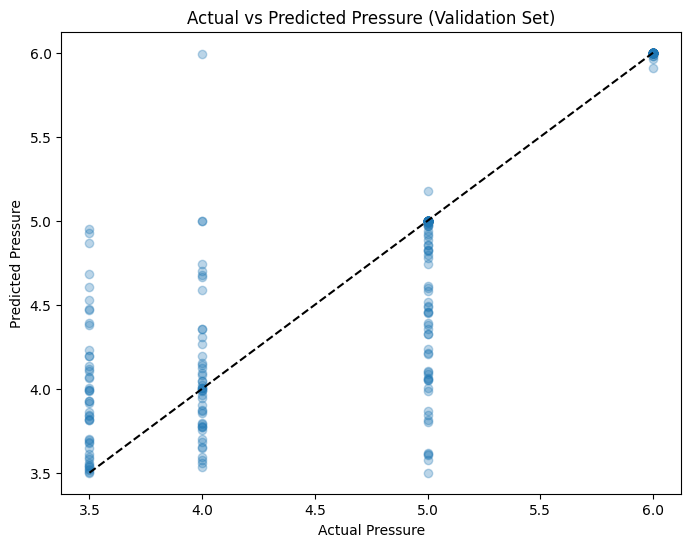

In [14]:
# %% [markdown]
"""
### Pressure Regression Validation
"""
# %% 
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Split the pressure dataset into training, validation, and test sets
X_pressure_train_val, X_pressure_test, y_pressure_train_val, y_pressure_test = train_test_split(
    X_pressure, y_pressure, test_size=0.2, random_state=42)
X_pressure_train, X_pressure_val, y_pressure_train, y_pressure_val = train_test_split(
    X_pressure_train_val, y_pressure_train_val, test_size=0.2, random_state=42)

# Preprocess the data using the regression pipeline
X_pressure_train_scaled = reg_preprocessor.fit_transform(X_pressure_train)
X_pressure_val_scaled = reg_preprocessor.transform(X_pressure_val)
X_pressure_test_scaled = reg_preprocessor.transform(X_pressure_test)

# Train the pressure regressor on the training data
pressure_reg = RandomForestRegressor(n_estimators=100, random_state=42)
pressure_reg.fit(X_pressure_train_scaled, y_pressure_train)

# Validate on the validation set
y_pressure_val_pred = pressure_reg.predict(X_pressure_val_scaled)
mse_val = mean_squared_error(y_pressure_val, y_pressure_val_pred)
r2_val = r2_score(y_pressure_val, y_pressure_val_pred)

print("Validation Pressure Regression Performance:")
print(f"Mean Squared Error: {mse_val:.2f}")
print(f"R-squared: {r2_val:.2f}")

# Optionally, visualize Actual vs Predicted pressure on the validation set
plt.figure(figsize=(8, 6))
plt.scatter(y_pressure_val, y_pressure_val_pred, alpha=0.3)
plt.plot([y_pressure_val.min(), y_pressure_val.max()], 
         [y_pressure_val.min(), y_pressure_val.max()], 'k--')
plt.xlabel('Actual Pressure')
plt.ylabel('Predicted Pressure')
plt.title('Actual vs Predicted Pressure (Validation Set)')
plt.show()
